# Análise de Vendas com Apache Spark

## Apresentação

Este projeto tem como objetivo demonstrar a utilização do Apache Spark para processamento e análise de dados utilizando Python e PySpark.

Foi utilizado o conjunto de dados público Brazilian E-Commerce Public Dataset by Olist, que contém informações sobre pedidos, produtos, clientes, vendedores e pagamentos de um marketplace brasileiro.

Para a realização das análises, foram selecionados 50.000 pedidos entregues. A partir desses dados, foram realizadas operações de integração, transformação, agrupamento e agregação.

**Tecnologias utilizadas:** Python, Apache Spark, PySpark, Pandas e Matplotlib.

**Ambiente de execução:** Google Colab, com processamento local.

In [1]:
import sys

print("Versão do Python:", sys.version)

!java -version

Versão do Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
[0.014s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.014s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [2]:
!pip install pyspark

In [3]:
import pyspark

print("PySpark instalado com sucesso!")
print("Versão:", pyspark.__version__)

PySpark instalado com sucesso!
Versão: 4.0.5


In [4]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("AnaliseDeVendas")
    .master("local[*]")
    .getOrCreate()
)

print("Apache Spark iniciado com sucesso!")
print("Versão do Spark:", spark.version)

Apache Spark iniciado com sucesso!
Versão do Spark: 4.0.5


In [5]:
spark

In [6]:
from google.colab import files

arquivos = files.upload()

Saving olist_dados.zip.zip to olist_dados.zip.zip


In [7]:
import zipfile
import os

arquivo_zip = list(arquivos.keys())[0]

pasta_dados = "/content/dados_olist"

os.makedirs(pasta_dados, exist_ok=True)

with zipfile.ZipFile(arquivo_zip, "r") as zip_ref:
    zip_ref.extractall(pasta_dados)

print("Arquivos extraídos com sucesso!")

Arquivos extraídos com sucesso!


In [8]:
for raiz, pastas, arquivos in os.walk(pasta_dados):
    for arquivo in arquivos:
        print(arquivo)

olist_customers_dataset.csv
olist_order_items_dataset.csv
olist_sellers_dataset.csv
olist_order_payments_dataset.csv
olist_orders_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_geolocation_dataset.csv
product_category_name_translation.csv


In [9]:
from pyspark.sql import functions as F

caminho = "/content/dados_olist"

arquivos_csv = {
    "pedidos": "olist_orders_dataset.csv",
    "itens": "olist_order_items_dataset.csv",
    "produtos": "olist_products_dataset.csv",
    "pagamentos": "olist_order_payments_dataset.csv",
    "clientes": "olist_customers_dataset.csv",
    "vendedores": "olist_sellers_dataset.csv",
    "avaliacoes": "olist_order_reviews_dataset.csv",
    "categorias": "product_category_name_translation.csv",
    "geolocalizacao": "olist_geolocation_dataset.csv"
}

dados = {}

for nome, arquivo in arquivos_csv.items():
    dados[nome] = (
        spark.read
        .option("header", True)
        .option("inferSchema", True)
        .csv(f"{caminho}/{arquivo}")
    )

print("Todos os arquivos foram carregados!")

Todos os arquivos foram carregados!


In [10]:
dados["pedidos"].show(10, truncate=False)

+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|delivered   |2017-10-02 10:56:33     |2017-10-02 11:07:15|2017-10-04 19:55:00         |2017-10-10 21:25:13          |2017-10-18 00:00:00          |
|53cdb2fc8bc7dce0b6741e2150273451|b0830fb4747a6c6d20dea0b8c802d7ef|delivered   |2018-07-24 20:41:37     |2018-07-26 03:24:27|2018-07-26 14:3

In [11]:
dados["itens"].show(10, truncate=False)

+--------------------------------+-------------+--------------------------------+--------------------------------+-------------------+------+-------------+
|order_id                        |order_item_id|product_id                      |seller_id                       |shipping_limit_date|price |freight_value|
+--------------------------------+-------------+--------------------------------+--------------------------------+-------------------+------+-------------+
|00010242fe8c5a6d1ba2dd792cb16214|1            |4244733e06e7ecb4970a6e2683c13e61|48436dade18ac8b2bce089ec2a041202|2017-09-19 09:45:35|58.9  |13.29        |
|00018f77f2f0320c557190d7a144bdd3|1            |e5f2d52b802189ee658865ca93d83a8f|dd7ddc04e1b6c2c614352b383efe2d36|2017-05-03 11:05:13|239.9 |19.93        |
|000229ec398224ef6ca0657da4fc703e|1            |c777355d18b72b67abbeef9df44fd0fd|5b51032eddd242adc84c38acab88f23d|2018-01-18 14:48:30|199.0 |17.87        |
|00024acbcdf0a6daa1e931b038114c75|1            |7634da152a4610f1

In [12]:
dados["produtos"].show(10, truncate=False)

+--------------------------------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+
|product_id                      |product_category_name|product_name_lenght|product_description_lenght|product_photos_qty|product_weight_g|product_length_cm|product_height_cm|product_width_cm|
+--------------------------------+---------------------+-------------------+--------------------------+------------------+----------------+-----------------+-----------------+----------------+
|1e9e8ef04dbcff4541ed26657ea517e5|perfumaria           |40                 |287                       |1                 |225             |16               |10               |14              |
|3aa071139cb16b67ca9e5dea641aaa2f|artes                |44                 |276                       |1                 |1000            |30               |18               |20              |
|96bd76ec8810374ed1b65e291975717f|e

In [13]:
dados["pagamentos"].show(10, truncate=False)

+--------------------------------+------------------+------------+--------------------+-------------+
|order_id                        |payment_sequential|payment_type|payment_installments|payment_value|
+--------------------------------+------------------+------------+--------------------+-------------+
|b81ef226f3fe1789b1e8b2acac839d17|1                 |credit_card |8                   |99.33        |
|a9810da82917af2d9aefd1278f1dcfa0|1                 |credit_card |1                   |24.39        |
|25e8ea4e93396b6fa0d3dd708e76c1bd|1                 |credit_card |1                   |65.71        |
|ba78997921bbcdc1373bb41e913ab953|1                 |credit_card |8                   |107.78       |
|42fdf880ba16b47b59251dd489d4441a|1                 |credit_card |2                   |128.45       |
|298fcdf1f73eb413e4d26d01b25bc1cd|1                 |credit_card |2                   |96.12        |
|771ee386b001f06208a7419e4fc1bbd7|1                 |credit_card |1               

In [14]:
for nome, df in dados.items():
    print(f"{nome}: {df.count()} registros")

pedidos: 99441 registros
itens: 112650 registros
produtos: 32951 registros
pagamentos: 103886 registros
clientes: 99441 registros
vendedores: 3095 registros
avaliacoes: 104162 registros
categorias: 71 registros
geolocalizacao: 1000163 registros


In [15]:
from pyspark.sql import functions as F
pedidos_amostra = (
    dados["pedidos"]
    .filter(F.col("order_status") == "delivered")
    .orderBy("order_purchase_timestamp", "order_id")
    .limit(50000)
)

print("Quantidade de pedidos selecionados:", pedidos_amostra.count())

Quantidade de pedidos selecionados: 50000


In [16]:
pedidos_amostra.select(
    "order_id",
    "order_status",
    "order_purchase_timestamp"
).show(10, truncate=False)

+--------------------------------+------------+------------------------+
|order_id                        |order_status|order_purchase_timestamp|
+--------------------------------+------------+------------------------+
|bfbd0f9bdef84302105ad712db648a6c|delivered   |2016-09-15 12:16:38     |
|3b697a20d9e427646d92567910af6d57|delivered   |2016-10-03 09:44:50     |
|be5bc2f0da14d8071e2d45451ad119d9|delivered   |2016-10-03 16:56:50     |
|a41c8759fbe7aab36ea07e038b2d4465|delivered   |2016-10-03 21:13:36     |
|d207cc272675637bfed0062edffd0818|delivered   |2016-10-03 22:06:03     |
|cd3b8574c82b42fc8129f6d502690c3e|delivered   |2016-10-03 22:31:31     |
|ae8a60e4b03c5a4ba9ca0672c164b181|delivered   |2016-10-03 22:44:10     |
|ef1b29b591d31d57c0d7337460dd83c9|delivered   |2016-10-03 22:51:30     |
|0a0837a5eee9e7a9ce2b1fa831944d27|delivered   |2016-10-04 09:06:10     |
|1ff217aa612f6cd7c4255c9bfe931c8b|delivered   |2016-10-04 09:16:33     |
+--------------------------------+------------+----

In [17]:
vendas = pedidos_amostra.join(
    dados["itens"],
    on="order_id",
    how="inner"
)
vendas = vendas.join(
    dados["produtos"].select(
        "product_id",
        "product_category_name"
    ),
    on="product_id",
    how="left"
)
vendas = vendas.join(
    dados["categorias"],
    on="product_category_name",
    how="left"
)
vendas = vendas.withColumn(
    "categoria",
    F.coalesce(
        F.col("product_category_name_english"),
        F.col("product_category_name"),
        F.lit("Não informado")
    )
)
print("Relacionamento concluído!")
print("Total de itens na amostra:", vendas.count())
vendas.select(
    "order_id",
    "order_purchase_timestamp",
    "product_id",
    "categoria",
    "price",
    "freight_value"
).show(10, truncate=False)

Relacionamento concluído!
Total de itens na amostra: 57015
+--------------------------------+------------------------+--------------------------------+---------------+-----+-------------+
|order_id                        |order_purchase_timestamp|product_id                      |categoria      |price|freight_value|
+--------------------------------+------------------------+--------------------------------+---------------+-----+-------------+
|00010242fe8c5a6d1ba2dd792cb16214|2017-09-13 08:59:02     |4244733e06e7ecb4970a6e2683c13e61|cool_stuff     |58.9 |13.29        |
|00018f77f2f0320c557190d7a144bdd3|2017-04-26 10:53:06     |e5f2d52b802189ee658865ca93d83a8f|pet_shop       |239.9|19.93        |
|000229ec398224ef6ca0657da4fc703e|2018-01-14 14:33:31     |c777355d18b72b67abbeef9df44fd0fd|furniture_decor|199.0|17.87        |
|00042b26cf59d7ce69dfabb4e55b4fd9|2017-02-04 13:57:51     |ac6c3623068f30de03045865e4e10089|garden_tools   |199.9|18.14        |
|00048cc3ae777c65dbb7d2a0634bc1ea|2017

## Análises e visualizações

Nesta etapa, são realizadas análises dos dados para identificar categorias com maior faturamento, evolução mensal das vendas, formas de pagamento e indicadores gerais.

Os resultados são apresentados por meio de tabelas e gráficos, utilizando as operações de processamento do Apache Spark e a biblioteca Matplotlib para visualização.

In [18]:
vendas_por_categoria = (
    vendas
    .groupBy("categoria")
    .agg(
        F.count("*").alias("quantidade_itens"),
        F.round(F.sum("price"), 2).alias("faturamento")
    )
    .orderBy(F.desc("faturamento"))
)

vendas_por_categoria.show(10, truncate=False)

+---------------------+----------------+-----------+
|categoria            |quantidade_itens|faturamento|
+---------------------+----------------+-----------+
|bed_bath_table       |5866            |556399.98  |
|watches_gifts        |2531            |542358.93  |
|health_beauty        |4190            |541948.25  |
|sports_leisure       |4533            |513088.53  |
|computers_accessories|3595            |461474.28  |
|cool_stuff           |2547            |418511.63  |
|furniture_decor      |4667            |380644.18  |
|toys                 |2725            |323664.39  |
|garden_tools         |2631            |282982.94  |
|auto                 |1796            |267309.86  |
+---------------------+----------------+-----------+
only showing top 10 rows


In [19]:
vendas_por_mes = (
    vendas
    .withColumn(
        "mes",
        F.date_format("order_purchase_timestamp", "yyyy-MM")
    )
    .groupBy("mes")
    .agg(
        F.count("*").alias("quantidade_itens"),
        F.round(F.sum("price"), 2).alias("faturamento")
    )
    .orderBy("mes")
)

vendas_por_mes.show(30, truncate=False)

+-------+----------------+-----------+
|mes    |quantidade_itens|faturamento|
+-------+----------------+-----------+
|2016-09|3               |134.97     |
|2016-10|313             |40325.11   |
|2016-12|1               |10.9       |
|2017-01|913             |111798.36  |
|2017-02|1858            |234223.4   |
|2017-03|2897            |359198.85  |
|2017-04|2569            |340669.68  |
|2017-05|4004            |489338.25  |
|2017-06|3489            |421923.37  |
|2017-07|4416            |481604.52  |
|2017-08|4797            |554699.7   |
|2017-09|4737            |607399.67  |
|2017-10|5214            |648247.65  |
|2017-11|8475            |987765.37  |
|2017-12|6187            |726033.19  |
|2018-01|7142            |831348.57  |
+-------+----------------+-----------+



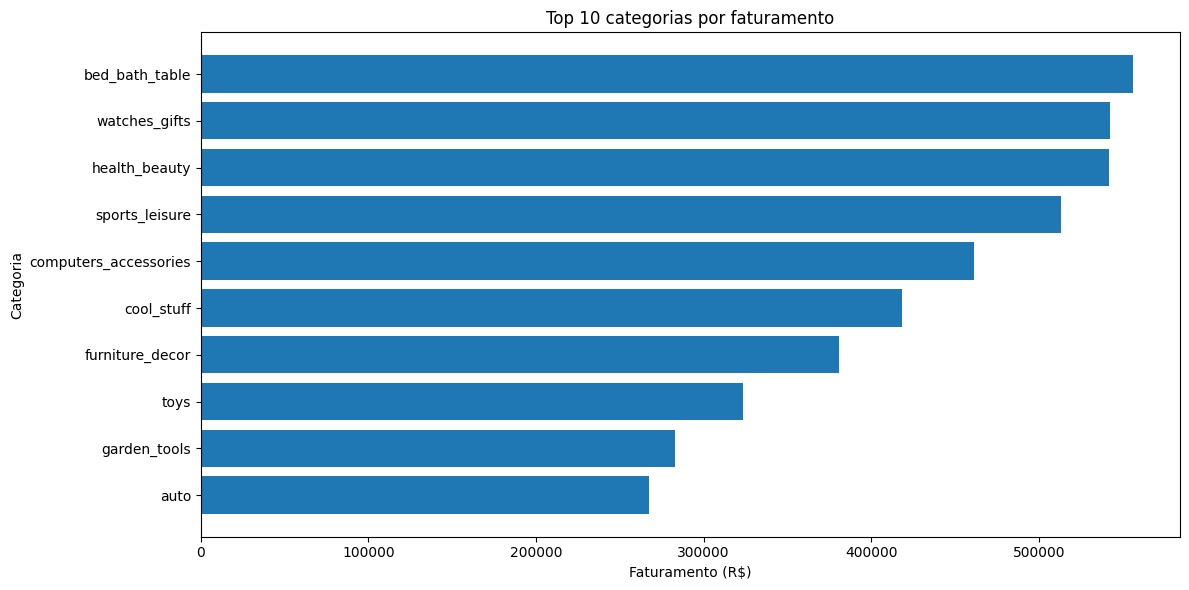

In [20]:
import matplotlib.pyplot as plt
df_categoria = vendas_por_categoria.limit(10).toPandas()
plt.figure(figsize=(12, 6))
plt.barh(
    df_categoria["categoria"],
    df_categoria["faturamento"]
)
plt.xlabel("Faturamento (R$)")
plt.ylabel("Categoria")
plt.title("Top 10 categorias por faturamento")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

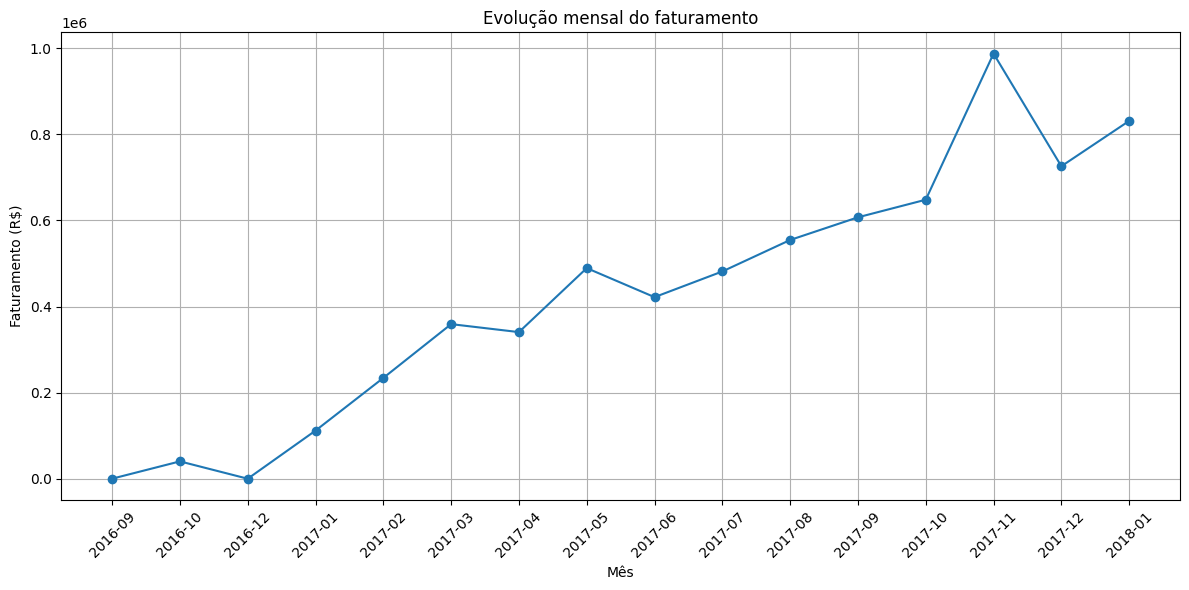

In [21]:
df_mensal = vendas_por_mes.toPandas()
plt.figure(figsize=(12, 6))
plt.plot(
    df_mensal["mes"],
    df_mensal["faturamento"],
    marker="o"
)
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.title("Evolução mensal do faturamento")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
pagamentos_amostra = dados["pagamentos"].join(
    pedidos_amostra.select("order_id"),
    on="order_id",
    how="inner"
)
pagamentos_por_tipo = (
    pagamentos_amostra
    .groupBy("payment_type")
    .agg(
        F.count("*").alias("quantidade_pagamentos"),
        F.round(F.sum("payment_value"), 2).alias("valor_total")
    )
    .orderBy(F.desc("valor_total"))
)
pagamentos_por_tipo.show(truncate=False)

+------------+---------------------+-----------+
|payment_type|quantidade_pagamentos|valor_total|
+------------+---------------------+-----------+
|credit_card |38310                |6179101.39 |
|boleto      |10503                |1516231.52 |
|voucher     |3257                 |190903.34  |
|debit_card  |505                  |52098.64   |
+------------+---------------------+-----------+



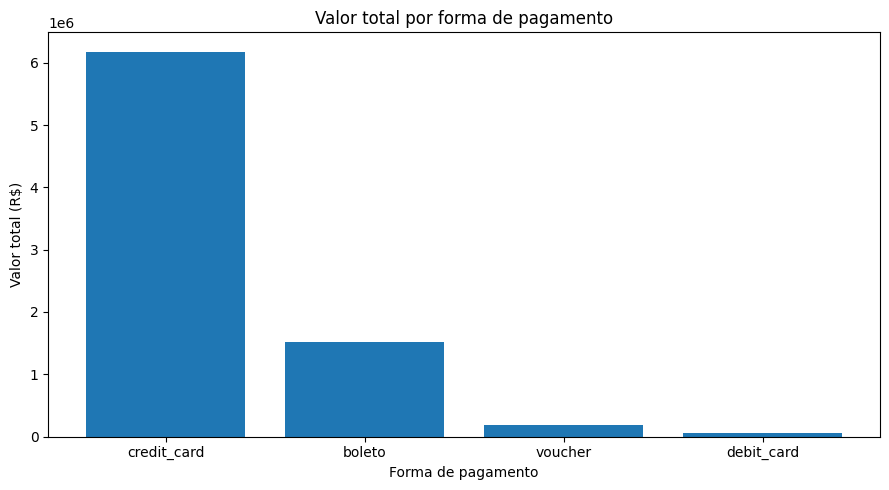

In [23]:
df_pagamentos = pagamentos_por_tipo.toPandas()
plt.figure(figsize=(9, 5))
plt.bar(
    df_pagamentos["payment_type"],
    df_pagamentos["valor_total"]
)
plt.xlabel("Forma de pagamento")
plt.ylabel("Valor total (R$)")
plt.title("Valor total por forma de pagamento")

plt.tight_layout()
plt.show()

In [24]:
indicadores = vendas.agg(
    F.count("*").alias("total_itens"),
    F.countDistinct("order_id").alias("total_pedidos"),
    F.round(F.sum("price"), 2).alias("faturamento_total"),
    F.round(F.avg("price"), 2).alias("preco_medio_item"),
    F.round(F.sum("freight_value"), 2).alias("frete_total")
)

indicadores.show(truncate=False)

+-----------+-------------+-----------------+----------------+-----------+
|total_itens|total_pedidos|faturamento_total|preco_medio_item|frete_total|
+-----------+-------------+-----------------+----------------+-----------+
|57015      |50000        |6834721.56       |119.88          |1101667.97 |
+-----------+-------------+-----------------+----------------+-----------+



In [25]:
print("Partições dos pedidos:", pedidos_amostra.rdd.getNumPartitions())
print("Partições das vendas:", vendas.rdd.getNumPartitions())

Partições dos pedidos: 1
Partições das vendas: 2


In [26]:
vendas_por_categoria.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [faturamento#507 DESC NULLS LAST], true, 0
   +- Exchange rangepartitioning(faturamento#507 DESC NULLS LAST, 200), ENSURE_REQUIREMENTS, [plan_id=4148]
      +- HashAggregate(keys=[categoria#446], functions=[count(1), sum(price#47)])
         +- Exchange hashpartitioning(categoria#446, 200), ENSURE_REQUIREMENTS, [plan_id=4145]
            +- HashAggregate(keys=[categoria#446], functions=[partial_count(1), partial_sum(price#47)])
               +- Project [price#47, coalesce(product_category_name_english#182, product_category_name#67, Não informado) AS categoria#446]
                  +- BroadcastHashJoin [product_category_name#67], [product_category_name#181], LeftOuter, BuildRight, false
                     :- Project [price#47, product_category_name#67]
                     :  +- BroadcastHashJoin [product_id#44], [product_id#66], LeftOuter, BuildRight, false
                     :     :- Project [product_id#44, price#47

In [27]:
import time
inicio = time.perf_counter()
resultado = (
    vendas
    .groupBy("categoria")
    .agg(F.round(F.sum("price"), 2).alias("faturamento"))
    .orderBy(F.desc("faturamento"))
)
resultado.show(10, truncate=False)
fim = time.perf_counter()
print(f"Tempo de execução: {(fim - inicio) * 1000:.2f} ms")

+---------------------+-----------+
|categoria            |faturamento|
+---------------------+-----------+
|bed_bath_table       |556399.98  |
|watches_gifts        |542358.93  |
|health_beauty        |541948.25  |
|sports_leisure       |513088.53  |
|computers_accessories|461474.28  |
|cool_stuff           |418511.63  |
|furniture_decor      |380644.18  |
|toys                 |323664.39  |
|garden_tools         |282982.94  |
|auto                 |267309.86  |
+---------------------+-----------+
only showing top 10 rows
Tempo de execução: 2104.23 ms


In [28]:
vendas_particionadas = vendas.repartition(4)
print(
    "Partições antes:",
    vendas.rdd.getNumPartitions()
)
print(
    "Partições depois:",
    vendas_particionadas.rdd.getNumPartitions()
)

Partições antes: 2
Partições depois: 4


In [29]:
vendas_particionadas.groupBy("categoria").count().show(10)

+--------------------+-----+
|           categoria|count|
+--------------------+-----+
|                 art|   48|
|             flowers|   18|
|   home_construction|  179|
|            pc_gamer|    4|
|fashion_male_clot...|  104|
|kitchen_dining_la...|  135|
|    small_appliances|  356|
|          la_cuisine|   11|
|      bed_bath_table| 5866|
|signaling_and_sec...|   52|
+--------------------+-----+
only showing top 10 rows


## Conclusão

O projeto permitiu aplicar conceitos do Apache Spark no processamento e na análise de dados de um conjunto de dados real.

Foram realizadas operações de leitura, integração, transformação, agrupamento e agregação, além da criação de visualizações para facilitar a interpretação dos resultados.

Também foram explorados recursos como particionamento, plano físico de execução e medição do tempo de processamento.

Com isso, foi possível compreender na prática como o PySpark pode ser utilizado para processar e analisar grandes conjuntos de dados.